In [55]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import chi2_contingency
from scipy.stats.contingency import association

In [3]:
df2 = pd.read_csv("amz_uk_price_prediction_dataset.csv")

In [5]:
df2

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers
...,...,...,...,...,...,...,...,...,...
2443646,2828589,B0CHSD7P2Q,"Motorbike Armour, Motorbike Clothing, Cycling ...",0.0,0,22.34,False,0,Motorbike Clothing
2443647,2828590,B0B7B8FNBQ,PROFIRST Waterproof Motorcycle 2 Piece Ladies ...,0.0,0,97.99,False,0,Motorbike Clothing
2443648,2828591,B0BD5FL5FB,Men’s Motorcycle Motorbike Biker Trousers Kevl...,0.0,0,52.99,False,0,Motorbike Clothing
2443649,2828592,B008OYLL4I,Texpeed Mens Motorcycle Motorbike Biker Trouse...,4.3,404,79.99,False,0,Motorbike Clothing


Part 1: Analyzing Best-Seller Trends Across Product Categories

Objective: Understand the relationship between product categories and their best-seller status.

1.Crosstab Analysis:

    1.1.Create a crosstab between the product category and the isBestSeller status.
    1.2.Are there categories where being a best-seller is more prevalent?

        Hint: one option is to calculate the proportion of best-sellers for each category and then sort the categories based on this proportion in descending order.

2.Statistical Tests:

    2.1.Conduct a Chi-square test to determine if the best-seller distribution is independent of the product category.
    2.2.Compute Cramér's V to understand the strength of association between best-seller status and category.

3.Visualizations:

    3.1.Visualize the relationship between product categories and the best-seller status using a stacked bar chart.

In [ ]:
# 1.1.

crosstab_result = pd.crosstab(df2['category'], df2['isBestSeller'])

crosstab_result

In [ ]:
# 1.2.

my_table = pd.crosstab(index = df2['isBestSeller'],  # Make a crosstab
                              columns="count")      # Name the count column
my_table

In [ ]:
(my_table/my_table.sum()).round(2)

In [ ]:
# 2.1.

p_value = chi2_contingency(crosstab_result) 
p_value

Chi2ContingencyResult(statistic=np.float64(36540.20270061387), pvalue=np.float64(0.0), dof=295, expected_freq=array([[2.47190130e+02, 8.09870149e-01],
       [4.05371878e+03, 1.32812173e+01],
       [2.49183599e+02, 8.16401360e-01],
       [1.69145827e+03, 5.54173243e+00],
       [2.53170536e+02, 8.29463782e-01],
       [8.50214439e+03, 2.78556144e+01],
       [1.06650580e+02, 3.49419782e-01],
       [2.57157474e+02, 8.42526204e-01],
       [9.51781673e+03, 3.11832664e+01],
       [1.50008526e+04, 4.91473619e+01],
       [9.32544700e+03, 3.05530045e+01],
       [2.38219520e+02, 7.80479700e-01],
       [3.22941944e+03, 1.05805616e+01],
       [9.44704859e+03, 3.09514084e+01],
       [6.68808779e+03, 2.19122125e+01],
       [5.26275760e+02, 1.72423967e+00],
       [1.90296531e+04, 6.23469391e+01],
       [2.77191835e+03, 9.08164873e+00],
       [2.53170536e+02, 8.29463782e-01],
       [4.04674164e+02, 1.32583581e+00],
       [1.92489346e+04, 6.30653723e+01],
       [3.10482764e+03, 1.017

In [56]:
# 2.2.

association(crosstab_result, method="cramer")

0.1222829439760564

In [ ]:
# The value from the Cramer V test, 0.1222 suggests a weak association between the 2 variables.

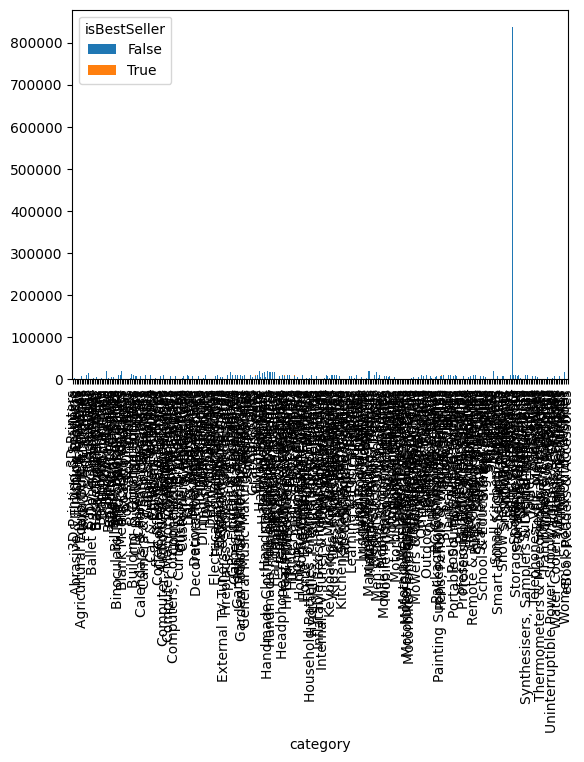

In [57]:
crosstab_result.plot(kind='bar', stacked=True)
plt.show()